In [1]:

import os

original_path = "/homes/nna272/Desktop/archive./OriginalDataset"
augmented_path = "/homes/nna272/Desktop/archive./AugmentedAlzheimerDataset"

for dataset_name, dataset_path in [
    ("Original Dataset", original_path),
    ("Augmented Dataset", augmented_path)
]:
    print(f"\n{'='*60}")
    print(dataset_name)
    print(f"{'='*60}")

    total_images = 0

    for category in sorted(os.listdir(dataset_path)):
        category_path = os.path.join(dataset_path, category)

        if os.path.isdir(category_path):
            count = len([
                f for f in os.listdir(category_path)
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp")
                )
            ])

            total_images += count
            print(f"{category}: {count} images")

    print(f"Total images: {total_images}")



Original Dataset
MildDemented: 896 images
ModerateDemented: 64 images
NonDemented: 3200 images
VeryMildDemented: 2240 images
Total images: 6400

Augmented Dataset
MildDemented: 8960 images
ModerateDemented: 6464 images
NonDemented: 9600 images
VeryMildDemented: 8960 images
Total images: 33984


In [2]:
task1_checkpoint = (
    "task1_syphilis/final_task1/"
    "task1_vdrl_model_with_fisher.pt"
)

In [3]:

import os
import hashlib
from collections import defaultdict

original_path = "/homes/nna272/Desktop/archive./OriginalDataset"
augmented_path = "/homes/nna272/Desktop/archive./AugmentedAlzheimerDataset"

def get_image_hashes(root):
    hashes = defaultdict(list)

    for category in os.listdir(root):
        category_path = os.path.join(root, category)

        if not os.path.isdir(category_path):
            continue

        for filename in os.listdir(category_path):
            filepath = os.path.join(category_path, filename)

            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            ):
                continue

            with open(filepath, "rb") as f:
                digest = hashlib.sha256(f.read()).hexdigest()

            hashes[digest].append((category, filename))

    return hashes


original_hashes = get_image_hashes(original_path)
augmented_hashes = get_image_hashes(augmented_path)

overlap = set(original_hashes) & set(augmented_hashes)

print("Original unique images:", len(original_hashes))
print("Augmented unique images:", len(augmented_hashes))
print("Exact duplicate images:", len(overlap))

print("\nSample original filenames:")
for category in os.listdir(original_path):
    folder = os.path.join(original_path, category)
    if os.path.isdir(folder):
        print(category, os.listdir(folder)[:5])


Original unique images: 6400
Augmented unique images: 33522
Exact duplicate images: 0

Sample original filenames:
MildDemented ['28 (27).jpg', 'mildDem110.jpg', 'mildDem225.jpg', 'mildDem464.jpg', 'mildDem179.jpg']
NonDemented ['28 (27).jpg', '32 (66).jpg', '29 (90).jpg', 'nonDem1267.jpg', 'nonDem804.jpg']
ModerateDemented ['moderateDem0.jpg', 'moderateDem18.jpg', '27 (2).jpg', 'moderateDem38.jpg', 'moderateDem26.jpg']
VeryMildDemented ['verymildDem442.jpg', '28 (27).jpg', '32 (66).jpg', 'verymildDem1281.jpg', 'verymildDem1787.jpg']


In [4]:

import os
import pandas as pd
from sklearn.model_selection import train_test_split

# Dataset
DATASET_PATH = "/homes/nna272/Desktop/archive./OriginalDataset"

OUTPUT_DIR = "task2_alzheimer"
os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42

CLASSES = [
    "MildDemented",
    "ModerateDemented",
    "NonDemented",
    "VeryMildDemented"
]

# Collect image paths and labels
samples = []

for label, category in enumerate(CLASSES):
    category_path = os.path.join(DATASET_PATH, category)

    for filename in os.listdir(category_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            samples.append({
                "image_path": os.path.join(category_path, filename),
                "class_name": category,
                "label": label
            })

df = pd.DataFrame(samples)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

# Save manifests
train_df.to_csv(f"{OUTPUT_DIR}/train.csv", index=False)
val_df.to_csv(f"{OUTPUT_DIR}/validation.csv", index=False)
test_df.to_csv(f"{OUTPUT_DIR}/test.csv", index=False)

print("Dataset split completed")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

for name, split in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name} distribution:")
    print(split["class_name"].value_counts().reindex(CLASSES))


Dataset split completed
Training: 4480
Validation: 960
Testing: 960

Training distribution:
class_name
MildDemented         627
ModerateDemented      45
NonDemented         2240
VeryMildDemented    1568
Name: count, dtype: int64

Validation distribution:
class_name
MildDemented        134
ModerateDemented     10
NonDemented         480
VeryMildDemented    336
Name: count, dtype: int64

Testing distribution:
class_name
MildDemented        135
ModerateDemented      9
NonDemented         480
VeryMildDemented    336
Name: count, dtype: int64


In [6]:
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize


# CONFIG
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ROOT = "task2_alzheimer"
CHECKPOINT_DIR = os.path.join(ROOT, "checkpoints")
RESULT_DIR = os.path.join(ROOT, "results")
FISHER_DIR = os.path.join(ROOT, "fisher")
FINAL_DIR = os.path.join(ROOT, "final_task2")

for directory in [
    CHECKPOINT_DIR, RESULT_DIR, FISHER_DIR, FINAL_DIR
]:
    os.makedirs(directory, exist_ok=True)

CLASSES = [
    "MildDemented",
    "ModerateDemented",
    "NonDemented",
    "VeryMildDemented"
]

NUM_CLASSES = 4
BATCH_SIZE = 32

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))





train_df = pd.read_csv(os.path.join(ROOT, "train.csv"))
val_df = pd.read_csv(os.path.join(ROOT, "validation.csv"))
test_df = pd.read_csv(os.path.join(ROOT, "test.csv"))


class AlzheimerDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")
        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label


# Training augmentation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and testing
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = AlzheimerDataset(
    train_df, train_transform
)

val_dataset = AlzheimerDataset(
    val_df, eval_transform
)

test_dataset = AlzheimerDataset(
    test_df, eval_transform
)



# WEIGHTED SAMPLING

class_counts = train_df["label"].value_counts().sort_index()

class_weights = 1.0 / class_counts.values

sample_weights = train_df["label"].map(
    lambda x: class_weights[int(x)]
).values

sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=4,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)



#  MODEL ARCHITECTURE

weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

in_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Linear(in_features, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(0.5),
    nn.Linear(256, NUM_CLASSES)
)

model = model.to(DEVICE)



# EVALUATION 


def evaluate(model, loader):

    model.eval()

    all_labels = []
    all_preds = []
    all_probs = []

    total_loss = 0.0

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, labels)

            probs = torch.softmax(outputs, dim=1)
            preds = outputs.argmax(dim=1)

            total_loss += loss.item() * labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            all_labels,
            all_preds,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0
        )
    )

    accuracy = accuracy_score(all_labels, all_preds)

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "macro_f1": f1,
        "labels": all_labels,
        "predictions": all_preds,
        "probabilities": all_probs
    }



# TRAINING FUNCTION

history = []


def train_stage(
    model,
    train_loader,
    val_loader,
    optimizer,
    epochs,
    stage_name,
    patience
):

    best_f1 = -1.0
    best_state = copy.deepcopy(model.state_dict())

    patience_counter = 0

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0

        for images, labels in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * labels.size(0)

        train_loss = running_loss / len(train_loader.dataset)

        val_metrics = evaluate(model, val_loader)

        scheduler.step(val_metrics["macro_f1"])

        print(
            f"{stage_name} | Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_metrics['loss']:.4f} | "
            f"Val Acc: {val_metrics['accuracy']:.4f} | "
            f"Val Macro-F1: {val_metrics['macro_f1']:.4f}"
        )

        history.append({
            "stage": stage_name,
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"]
        })

        if val_metrics["macro_f1"] > best_f1:

            best_f1 = val_metrics["macro_f1"]

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

        else:

            patience_counter += 1

        if patience_counter >= patience:
            print("Early stopping activated.")
            break

    model.load_state_dict(best_state)

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "best_val_macro_f1": best_f1,
            "stage": stage_name,
            "classes": CLASSES
        },
        os.path.join(
            CHECKPOINT_DIR,
            f"{stage_name}_best.pt"
        )
    )

    return model


#  TRANSFER LEARNING


print("\n========== STAGE 1: TRANSFER LEARNING ==========")

for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

optimizer = optim.AdamW(
    model.fc.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

model = train_stage(
    model,
    train_loader,
    val_loader,
    optimizer,
    epochs=10,
    stage_name="stage1_transfer",
    patience=5
)


#  FINE-TUNING

print("\n========== STAGE 2: FINE-TUNING ==========")

# Unfreeze layer4 and classifier first
for param in model.layer4.parameters():
    param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True

optimizer = optim.AdamW(
    [
        {
            "params": model.layer1.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.layer2.parameters(),
            "lr": 1e-5
        },
        {
            "params": model.layer3.parameters(),
            "lr": 5e-5
        },
        {
            "params": model.layer4.parameters(),
            "lr": 1e-4
        },
        {
            "params": model.fc.parameters(),
            "lr": 3e-4
        }
    ],
    weight_decay=0.0001
)

# Gradually unfreezing the entire backbone.
for param in model.layer1.parameters():
    param.requires_grad = True

for param in model.layer2.parameters():
    param.requires_grad = True

for param in model.layer3.parameters():
    param.requires_grad = True

model = train_stage(
    model,
    train_loader,
    val_loader,
    optimizer,
    epochs=30,
    stage_name="stage2_finetuned",
    patience=7
)



print("\n========== FINAL TEST EVALUATION ==========")

test_metrics = evaluate(model, test_loader)

print("Test Accuracy:", test_metrics["accuracy"])
print("Test Precision:", test_metrics["precision"])
print("Test Recall:", test_metrics["recall"])
print("Test Macro-F1:", test_metrics["macro_f1"])

print("\nClassification Report:")

print(
    classification_report(
        test_metrics["labels"],
        test_metrics["predictions"],
        labels=np.arange(NUM_CLASSES),
        target_names=CLASSES,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

cm = confusion_matrix(
    test_metrics["labels"],
    test_metrics["predictions"],
    labels=np.arange(NUM_CLASSES)
)

print(cm)



y_true_binary = label_binarize(
    test_metrics["labels"],
    classes=np.arange(NUM_CLASSES)
)

try:
    auc = roc_auc_score(
        y_true_binary,
        test_metrics["probabilities"],
        average="macro",
        multi_class="ovr"
    )

    print("Macro ROC-AUC:", auc)

except ValueError as e:
    print("ROC-AUC could not be calculated:", e)




pd.DataFrame(history).to_csv(
    os.path.join(RESULT_DIR, "training_history.csv"),
    index=False
)

with open(
    os.path.join(RESULT_DIR, "classification_report.txt"),
    "w"
) as f:

    f.write(
        classification_report(
            test_metrics["labels"],
            test_metrics["predictions"],
            labels=np.arange(NUM_CLASSES),
            target_names=CLASSES,
            zero_division=0
        )
    )

np.save(
    os.path.join(RESULT_DIR, "confusion_matrix.npy"),
    cm
)

print("\nTask 2 training completed.")


Device: cuda
GPU: NVIDIA GeForce RTX 3080

========== STAGE 1: TRANSFER LEARNING ==========
stage1_transfer | Epoch 1/10 | Train Loss: 1.1866 | Val Loss: 1.1342 | Val Acc: 0.4302 | Val Macro-F1: 0.3186
stage1_transfer | Epoch 2/10 | Train Loss: 0.9949 | Val Loss: 1.0298 | Val Acc: 0.5104 | Val Macro-F1: 0.3513
stage1_transfer | Epoch 3/10 | Train Loss: 0.9409 | Val Loss: 0.9787 | Val Acc: 0.5240 | Val Macro-F1: 0.4088
stage1_transfer | Epoch 4/10 | Train Loss: 0.9164 | Val Loss: 1.0324 | Val Acc: 0.4802 | Val Macro-F1: 0.3786
stage1_transfer | Epoch 5/10 | Train Loss: 0.9076 | Val Loss: 0.9151 | Val Acc: 0.5865 | Val Macro-F1: 0.4679
stage1_transfer | Epoch 6/10 | Train Loss: 0.8829 | Val Loss: 0.9994 | Val Acc: 0.4948 | Val Macro-F1: 0.4376
stage1_transfer | Epoch 7/10 | Train Loss: 0.8623 | Val Loss: 0.9695 | Val Acc: 0.4875 | Val Macro-F1: 0.4733
stage1_transfer | Epoch 8/10 | Train Loss: 0.8452 | Val Loss: 1.0243 | Val Acc: 0.4698 | Val Macro-F1: 0.4160
stage1_transfer | Epoch 9/10

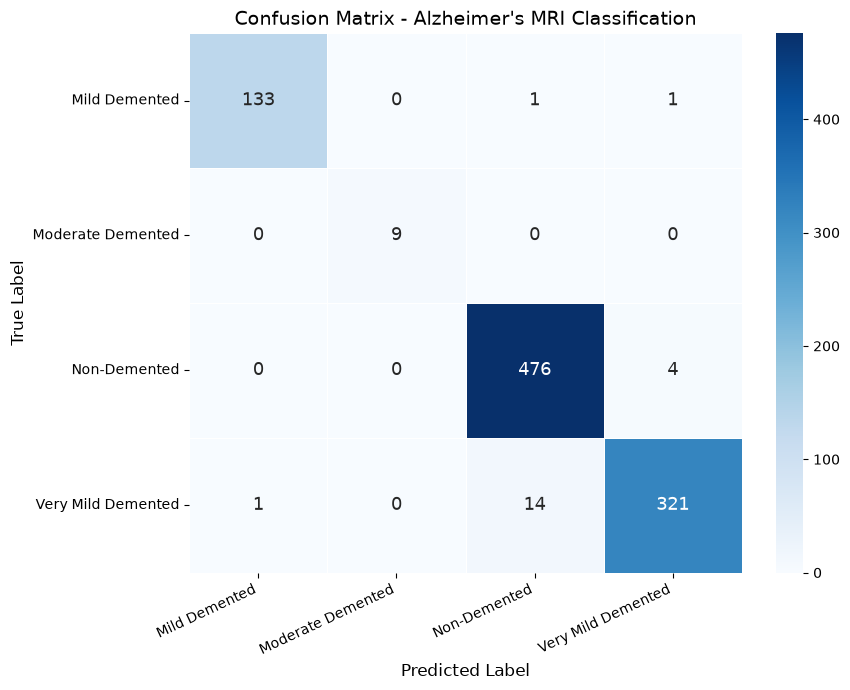

Confusion matrix saved.


In [7]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    test_metrics["labels"],
    test_metrics["predictions"],
    labels=[0, 1, 2, 3]
)

class_names = [
    "Mild Demented",
    "Moderate Demented",
    "Non-Demented",
    "Very Mild Demented"
]

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    cbar=True,
    annot_kws={"size": 13}
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)

plt.title(
    "Confusion Matrix - Alzheimer's MRI Classification",
    fontsize=14
)

plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved.")


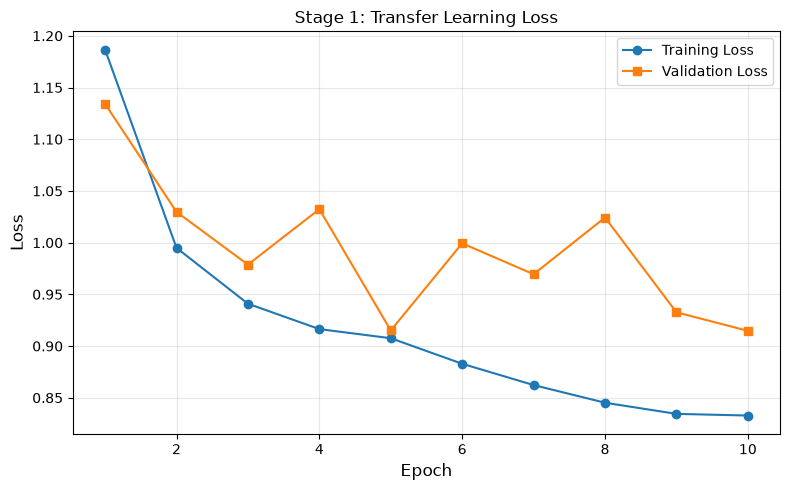

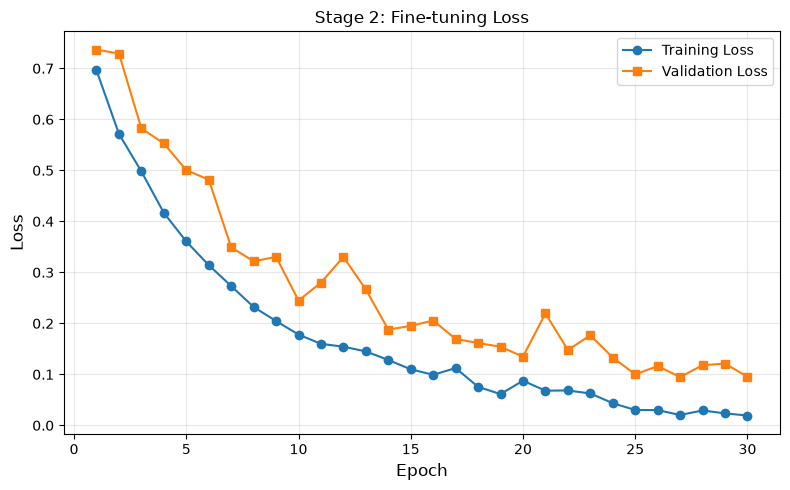

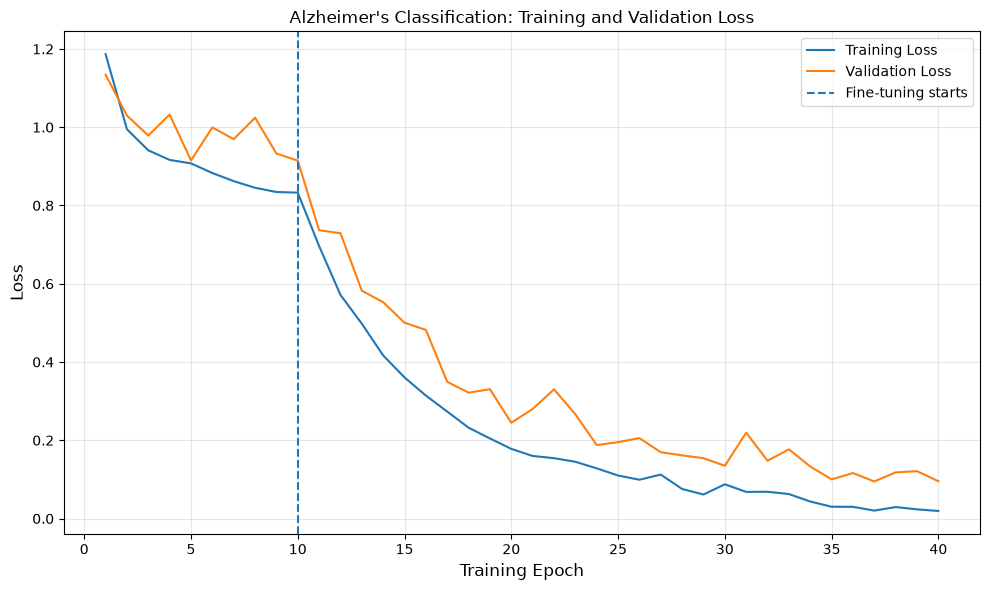

Loss plots saved successfully.


In [8]:

import os
import pandas as pd
import matplotlib.pyplot as plt

RESULT_DIR = "task2_alzheimer/results"
os.makedirs(RESULT_DIR, exist_ok=True)

history_df = pd.DataFrame(history)

# ------------------------------------------------
# Plot 1: Stage 1 - Transfer Learning
# ------------------------------------------------

stage1 = history_df[
    history_df["stage"] == "stage1_transfer"
]

plt.figure(figsize=(8, 5))

plt.plot(
    stage1["epoch"],
    stage1["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    stage1["epoch"],
    stage1["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Stage 1: Transfer Learning Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/stage1_transfer_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------
# Plot 2: Stage 2 - Fine-tuning
# ------------------------------------------------

stage2 = history_df[
    history_df["stage"] == "stage2_finetuned"
]

plt.figure(figsize=(8, 5))

plt.plot(
    stage2["epoch"],
    stage2["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    stage2["epoch"],
    stage2["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Stage 2: Fine-tuning Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/stage2_finetuning_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------
# Plot 3: Combined Training History
# ------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(history_df) + 1),
    history_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    range(1, len(history_df) + 1),
    history_df["val_loss"],
    label="Validation Loss"
)

boundary = len(stage1)

plt.axvline(
    x=boundary,
    linestyle="--",
    label="Fine-tuning starts"
)

plt.xlabel("Training Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Alzheimer's Classification: Training and Validation Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/combined_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Loss plots saved successfully.")


In [9]:

import json
import numpy as np
import os

# Save numerical confusion matrix
np.save(
    f"{RESULT_DIR}/confusion_matrix.npy",
    cm
)

# Save training history
history_df.to_csv(
    f"{RESULT_DIR}/training_history.csv",
    index=False
)

# Save test metrics
results = {
    "accuracy": float(test_metrics["accuracy"]),
    "precision": float(test_metrics["precision"]),
    "recall": float(test_metrics["recall"]),
    "macro_f1": float(test_metrics["macro_f1"]),
    "macro_auc": float(auc)
}

with open(
    f"{RESULT_DIR}/test_results.json",
    "w"
) as f:
    json.dump(results, f, indent=4)

print("All Task 2 plots and results saved.")


All Task 2 plots and results saved.


In [10]:

# TASK 2: FISHER INFORMATION ESTIMATION
from torch.utils.data import DataLoader

FISHER_SAMPLES = len(train_dataset)

print("Fisher sample size:", FISHER_SAMPLES)

# IMPORTANT:
# Use original training images without random augmentation.
# Do not use the weighted replacement sampler for Fisher.

fisher_dataset = AlzheimerDataset(
    train_df,
    transform=eval_transform
)

fisher_loader = DataLoader(
    fisher_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

model.eval()

fisher_information = {
    name: torch.zeros_like(param, device=DEVICE)
    for name, param in model.named_parameters()
    if param.requires_grad
}

criterion = nn.CrossEntropyLoss(reduction="sum")

total_samples = 0

for images, labels in fisher_loader:

    images = images.to(DEVICE)
    labels = labels.to(DEVICE)

    model.zero_grad(set_to_none=True)

    outputs = model(images)

    loss = criterion(outputs, labels)

    loss.backward()

    batch_size = labels.size(0)

    for name, param in model.named_parameters():

        if param.requires_grad and param.grad is not None:

            fisher_information[name] += (
                param.grad.detach() ** 2
            )

    total_samples += batch_size

# Normalize Fisher values
for name in fisher_information:

    fisher_information[name] /= total_samples


# Save optimal parameters
theta_star = {
    name: param.detach().clone()
    for name, param in model.named_parameters()
    if param.requires_grad
}


# Fisher statistics

all_fisher_values = torch.cat([
    value.detach().flatten().cpu()
    for value in fisher_information.values()
])

print("\nFisher Information Summary")
print("--------------------------------")
print("Samples:", total_samples)
print("Parameters:", all_fisher_values.numel())
print("Mean:", all_fisher_values.mean().item())
print("Maximum:", all_fisher_values.max().item())
print("Minimum:", all_fisher_values.min().item())
print("Non-zero:", torch.count_nonzero(all_fisher_values).item())

# Save complete Task 2 checkpoint

final_checkpoint = {

    "task_name": "Alzheimer MRI Classification",

    "model_name": "ResNet18",

    "model_state_dict": model.state_dict(),

    "fisher_information": fisher_information,

    "theta_star": theta_star,

    "classes": CLASSES,

    "num_classes": NUM_CLASSES,

    "input_size": 224,

    "test_results": {
        "accuracy": test_metrics["accuracy"],
        "precision": test_metrics["precision"],
        "recall": test_metrics["recall"],
        "macro_f1": test_metrics["macro_f1"],
        "macro_auc": auc
    },

    "fisher_samples": total_samples,

    "training_method": [
        "ImageNet Transfer Learning",
        "ResNet18 Fine-tuning"
    ]
}

save_path = os.path.join(
    FINAL_DIR,
    "task2_alzheimer_with_fisher.pt"
)

torch.save(final_checkpoint, save_path)

print("\nTask 2 Fisher checkpoint saved:")
print(save_path)

print("\nTask 2 completed successfully.")


Fisher sample size: 4480

Fisher Information Summary
--------------------------------
Samples: 4480
Parameters: 11299332
Mean: 0.00021988408116158098
Maximum: 3.0151736736297607
Minimum: 0.0
Non-zero: 11208805

Task 2 Fisher checkpoint saved:
task2_alzheimer/final_task2/task2_alzheimer_with_fisher.pt

Task 2 completed successfully.
